In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd, glob, os

ANA = '/content/drive/MyDrive/NASA_JARVION/Veri'
SUTUNLAR = ['latitude', 'longitude', 'acq_date', 'satellite',
            'confidence', 'frp', 'daynight', 'type']

def oku(klasor, sensor):
    parcalar = []
    for yol in sorted(glob.glob(f'{ANA}/{klasor}/*.csv')):
        d = pd.read_csv(yol, usecols=lambda s: s in SUTUNLAR)
        d['dosya'] = os.path.basename(yol)
        parcalar.append(d)
    t = pd.concat(parcalar, ignore_index=True)
    t['sensor'] = sensor
    t['surum'] = t['dosya'].str.startswith('fire_nrt').map({True: 'nrt', False: 'sp'})
    t['tarih'] = pd.to_datetime(t['acq_date'])
    t['yil'] = t['tarih'].dt.year
    t['ay'] = t['tarih'].dt.month
    print(sensor, '| dosya:', len(parcalar), '| satır:', len(t),
          '|', t['tarih'].min().date(), '-', t['tarih'].max().date())
    return t

modis  = oku('modis', 'MODIS')
snpp   = oku('viirs-snpp', 'SNPP')
noaa20 = oku('viirs-noaa20', 'NOAA20')

MODIS | dosya: 28 | satır: 259708 | 2000-11-01 - 2026-11-13
SNPP | dosya: 16 | satır: 637595 | 2012-01-20 - 2026-11-02
NOAA20 | dosya: 10 | satır: 360957 | 2018-04-01 - 2026-11-12


In [ ]:
kontrol = pd.concat([modis, snpp, noaa20]).groupby(['yil', 'sensor']).size().unstack()
kontrol

sensor,MODIS,NOAA20,SNPP
yil,,,
2000,496.0,NaN,NaN
2001,5162.0,NaN,NaN
2002,6886.0,NaN,NaN
2003,7733.0,NaN,NaN
2004,7901.0,NaN,NaN
2005,8303.0,NaN,NaN
2006,9459.0,NaN,NaN
2007,8791.0,NaN,NaN
2008,6164.0,NaN,NaN


In [ ]:
def ayikla(t, ad):
    t = t.copy()
    # Her noktayı yaklaşık 1 km'lik bir kareye yerleştir
    t['kare'] = t['latitude'].round(2).astype(str) + '_' + t['longitude'].round(2).astype(str)
    sp, nrt = t[t['surum'] == 'sp'], t[t['surum'] == 'nrt']

    # Kalite kontrollü veride yangın olmayan noktaların bulunduğu kareler
    sabit = set(sp.loc[sp['type'] != 0, 'kare'])

    # Bu "kare listesi" yöntemi ne kadar iyi? 2025'te deneyelim:
    egitim = set(sp.loc[(sp['type'] != 0) & (sp['yil'] < 2025), 'kare'])
    t25 = sp[sp['yil'] == 2025]
    yakalanan = t25.loc[t25['type'] != 0, 'kare'].isin(egitim).mean()
    yanlis = t25.loc[t25['type'] == 0, 'kare'].isin(egitim).mean()
    print(f'{ad}: sabit kaynakların %{yakalanan*100:.0f} kadarı yakalandı, '
          f'gerçek yangınların %{yanlis*100:.1f} kadarı yanlışlıkla atıldı')

    yangin = pd.concat([sp[sp['type'] == 0], nrt[~nrt['kare'].isin(sabit)]])
    print(f'   {len(t)} satırdan {len(yangin)} yangın satırı kaldı')
    return yangin

modis_y  = ayikla(modis, 'MODIS')
snpp_y   = ayikla(snpp, 'SNPP')
noaa20_y = ayikla(noaa20, 'NOAA20')

MODIS: sabit kaynakların %75 kadarı yakalandı, gerçek yangınların %1.8 kadarı yanlışlıkla atıldı
   259708 satırdan 251289 yangın satırı kaldı
SNPP: sabit kaynakların %98 kadarı yakalandı, gerçek yangınların %3.6 kadarı yanlışlıkla atıldı
   637595 satırdan 467321 yangın satırı kaldı
NOAA20: sabit kaynakların %99 kadarı yakalandı, gerçek yangınların %3.0 kadarı yanlışlıkla atıldı
   360957 satırdan 250339 yangın satırı kaldı


In [ ]:
def aylik(t):
    s = t.groupby(['yil', 'ay']).size()
    # Uydunun çalıştığı dönemde hiç tespit olmayan aylar 0 sayılır
    ilk, son = t['tarih'].min(), t['tarih'].max()
    tum = pd.period_range(ilk, son, freq='M')
    idx = pd.MultiIndex.from_arrays([tum.year, tum.month], names=['yil', 'ay'])
    return s.reindex(idx, fill_value=0)

ay = pd.DataFrame({'MODIS': aylik(modis_y), 'SNPP': aylik(snpp_y), 'NOAA20': aylik(noaa20_y)})
print(len(ay), 'ay')
ay.loc[2021]

313 ay


,MODIS,SNPP,NOAA20
ay,,,
1,430,1116.0,1181.0
2,310,773.0,830.0
3,97,492.0,520.0
4,81,284.0,339.0
5,304,873.0,856.0
6,1026,2697.0,2864.0
7,1862,5691.0,6209.0
8,2067,6842.0,7253.0
9,363,2585.0,2740.0


In [ ]:
ay = ay.sort_index()

# İki uydunun birlikte ve tam çalıştığı aylar: Şubat 2012 - Aralık 2025
ortak = ay.loc[(2012, 2):(2025, 12)]
k_genel = ortak['SNPP'].sum() / ortak['MODIS'].sum()
print('Genel katsayı:', round(k_genel, 2))
print('\nAya göre katsayı:')
print((ortak.groupby('ay')['SNPP'].sum() / ortak.groupby('ay')['MODIS'].sum()).round(2).to_string())
print('\nYıla göre katsayı:')
print((ortak.groupby('yil')['SNPP'].sum() / ortak.groupby('yil')['MODIS'].sum()).round(2).to_string())

# Hızlı sürüm verisi içeren aylar
n = snpp_y[snpp_y['surum'] == 'nrt']
nrt_aylar = set(zip(n['yil'], n['ay']))

satirlar = []
for (y, m), r in ay.iterrows():
    note = ''
    if (y, m) < (2012, 1):
        h, src = round(r['MODIS'] * k_genel), 'MODIS_converted'
        if (y, m) < (2002, 7):
            conf, note = 'low', 'Converted from MODIS; Terra only'
        else:
            conf, note = 'medium', 'Converted from MODIS'
    elif (y, m) < (2026, 11):
        h, src = int(r['SNPP']), 'VIIRS_SNPP'
        if (y, m) == (2012, 1):
            conf, note = 'medium', 'Partial month'
        elif (y, m) in nrt_aylar:
            conf, note = 'medium', 'Near real-time data'
        else:
            conf = 'high'
    else:
        h, src = int(r['NOAA20']), 'VIIRS_NOAA20'
        conf, note = 'medium', 'Partial month; near real-time data'
    satirlar.append([y, m, h, h, h, src, conf, note])

takvim = pd.DataFrame(satirlar, columns=['year', 'month', 'hotspots', 'lower',
                                         'upper', 'source', 'confidence', 'note'])
takvim.to_csv('/content/drive/MyDrive/NASA_JARVION/Kod/calendar_turkey.csv', index=False)
print('\nKaydedildi:', len(takvim), 'satır')
takvim.pivot(index='year', columns='month', values='hotspots')

Genel katsayı: 3.38

Aya göre katsayı:
ay
1     3.10
2     3.02
3     3.58
4     3.71
5     1.82
6     2.13
7     3.16
8     4.39
9     4.77
10    3.91
11    2.55
12    3.01

Yıla göre katsayı:
yil
2012    3.54
2013    3.49
2014    3.32
2015    3.14
2016    3.49
2017    3.33
2018    3.53
2019    3.76
2020    3.95
2021    3.16
2022    3.07
2023    3.44
2024    3.18
2025    3.14

Kaydedildi: 313 satır


month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1574.0,81.0
2001,152.0,128.0,341.0,172.0,699.0,1821.0,1416.0,2797.0,5399.0,3622.0,747.0,3.0
2002,37.0,152.0,189.0,240.0,514.0,2943.0,3135.0,4598.0,6112.0,3439.0,1669.0,115.0
2003,122.0,30.0,615.0,534.0,807.0,7581.0,3010.0,2932.0,4770.0,2878.0,2426.0,101.0
2004,7.0,233.0,818.0,568.0,713.0,3838.0,1807.0,3139.0,7615.0,5128.0,2182.0,416.0
2005,277.0,253.0,534.0,473.0,764.0,5514.0,2902.0,3439.0,6943.0,4426.0,1507.0,764.0
2006,101.0,193.0,473.0,311.0,1091.0,5622.0,3189.0,7970.0,7304.0,2655.0,1919.0,848.0
2007,260.0,169.0,652.0,689.0,611.0,5966.0,4017.0,4128.0,8091.0,3412.0,875.0,571.0
2008,385.0,314.0,375.0,260.0,794.0,4439.0,2223.0,2514.0,4747.0,2568.0,1436.0,449.0


In [ ]:
import numpy as np

o = ortak.reset_index()

def tahmin_et(egitim, test, model):
    if model == 'tek katsayı':
        return test['MODIS'] * egitim['SNPP'].sum() / egitim['MODIS'].sum()
    if model == 'aylık katsayı':
        g = egitim.groupby('ay')[['SNPP', 'MODIS']].sum()
        return test['MODIS'] * test['ay'].map(g['SNPP'] / g['MODIS'])
    if model == 'eğri':
        b, a = np.polyfit(np.log(egitim['MODIS'] + 1), np.log(egitim['SNPP'] + 1), 1)
        return np.exp(a + b * np.log(test['MODIS'] + 1)) - 1

cv = {}
for model in ['tek katsayı', 'aylık katsayı', 'eğri']:
    parcalar = []
    for yil in sorted(o['yil'].unique()):
        egitim, test = o[o['yil'] != yil], o[o['yil'] == yil].copy()
        test['tahmin'] = tahmin_et(egitim, test, model)
        parcalar.append(test)
    s = pd.concat(parcalar)
    cv[model] = s
    aylik_hata = (s['tahmin'] - s['SNPP']).abs().sum() / s['SNPP'].sum()
    y = s.groupby('yil')[['tahmin', 'SNPP']].sum()
    yillik_hata = ((y['tahmin'] - y['SNPP']).abs() / y['SNPP']).mean()
    yogun = s[s['ay'].isin([6, 7, 8, 9, 10])]
    yogun_hata = (yogun['tahmin'] - yogun['SNPP']).abs().sum() / yogun['SNPP'].sum()
    print(f'{model:14s} | aylık hata: %{aylik_hata*100:.0f} | '
          f'yoğun aylar: %{yogun_hata*100:.0f} | yıllık toplam hatası: %{yillik_hata*100:.0f}')

tek katsayı    | aylık hata: %29 | yoğun aylar: %28 | yıllık toplam hatası: %6
aylık katsayı  | aylık hata: %13 | yoğun aylar: %11 | yıllık toplam hatası: %4
eğri           | aylık hata: %29 | yoğun aylar: %30 | yıllık toplam hatası: %8


In [ ]:
KOD = '/content/drive/MyDrive/NASA_JARVION/Kod'
YOGUN = [6, 7, 8, 9, 10]

# 1) Son katsayılar: her takvim ayı için ayrı, 14 ortak yılın tamamından
g = ortak.groupby('ay')[['SNPP', 'MODIS']].sum()
k_ay = g['SNPP'] / g['MODIS']

# 2) Aralık: testte "gerçek / tahmin" oranı ne kadar oynadı?
s = cv['aylık katsayı'].copy()
s = s[s['tahmin'] > 0]
s['oran'] = s['SNPP'] / s['tahmin']
s['yogun'] = s['ay'].isin(YOGUN)
q = s.groupby('yogun')['oran'].quantile([0.1, 0.9]).unstack()
print('Aralık çarpanları (alt, üst):')
print(q.round(2).rename(index={True: 'yoğun aylar', False: 'diğer aylar'}).to_string())
s['alt'], s['ust'] = s['yogun'].map(q[0.1]), s['yogun'].map(q[0.9])
kapsama = ((s['SNPP'] >= s['tahmin'] * s['alt']) & (s['SNPP'] <= s['tahmin'] * s['ust'])).mean()
print(f'Testte gerçek değerlerin %{kapsama*100:.0f} kadarı aralığın içinde kaldı')

# 3) İki VIIRS uydusu ne kadar yakın sayıyor? (2018-2025)
o2 = ay.loc[(2018, 4):(2025, 12)]
print('NOAA-20 / S-NPP oranı:', round(o2['NOAA20'].sum() / o2['SNPP'].sum(), 3))

# 4) Takvim tablosu
satirlar = []
for (y, m), r in ay.iterrows():
    note = ''
    if (y, m) < (2012, 2):
        h = r['MODIS'] * k_ay[m]
        lo, up = h * q.loc[m in YOGUN, 0.1], h * q.loc[m in YOGUN, 0.9]
        src = 'MODIS_converted'
        if (y, m) < (2002, 7):
            conf, note = 'low', 'Converted from MODIS; Terra only'
        else:
            conf, note = 'medium', 'Converted from MODIS'
    elif (y, m) < (2026, 11):
        h = lo = up = r['SNPP']
        src = 'VIIRS_SNPP'
        conf, note = ('medium', 'Near real-time data') if (y, m) in nrt_aylar else ('high', '')
    else:
        h = lo = up = r['NOAA20']
        src, conf, note = 'VIIRS_NOAA20', 'medium', 'Partial month; near real-time data'
    satirlar.append([y, m, round(h), round(lo), round(up), src, conf, note])

takvim = pd.DataFrame(satirlar, columns=['year', 'month', 'hotspots', 'lower',
                                         'upper', 'source', 'confidence', 'note'])
takvim.to_csv(f'{KOD}/calendar_turkey.csv', index=False)

# 5) Kareli tablo (yarım derecelik kareler)
def kareli(t):
    t = t.assign(lat=np.floor(t['latitude'] * 2) / 2, lon=np.floor(t['longitude'] * 2) / 2)
    k = t.groupby(['yil', 'ay', 'lat', 'lon']).size().rename('n').reset_index()
    k['d'] = k['yil'] * 100 + k['ay']
    return k

gm, gs, gn = kareli(modis_y), kareli(snpp_y), kareli(noaa20_y)
gm = gm[gm['d'] < 201202].copy()
gm['hotspots'] = gm['n'] * gm['ay'].map(k_ay)
gs = gs[(gs['d'] >= 201202) & (gs['d'] < 202611)].copy()
gs['hotspots'] = gs['n']
gn = gn[gn['d'] >= 202611].copy()
gn['hotspots'] = gn['n']
grid = pd.concat([gm, gs, gn]).rename(columns={'yil': 'year', 'ay': 'month'})
grid = grid[['year', 'month', 'lat', 'lon', 'hotspots']]
grid['hotspots'] = grid['hotspots'].round(1)
grid.to_csv(f'{KOD}/grid_turkey.csv', index=False)

# 6) Kontrol: karelerin toplamı ülke toplamına eşit mi?
fark = (grid.groupby(['year', 'month'])['hotspots'].sum()
        - takvim.set_index(['year', 'month'])['hotspots']).abs().max()
print(f'\nTakvim: {len(takvim)} satır | Kareli tablo: {len(grid)} satır | '
      f'En büyük toplam farkı: {fark:.1f}')
print('\nAylık katsayılar:')
print(k_ay.round(2).to_string())
takvim[takvim['year'].isin([2005, 2021])]

Aralık çarpanları (alt, üst):
              0.1   0.9
yogun                  
diğer aylar  0.72  1.49
yoğun aylar  0.85  1.29
Testte gerçek değerlerin %80 kadarı aralığın içinde kaldı
NOAA-20 / S-NPP oranı: 1.021

Takvim: 313 satır | Kareli tablo: 44387 satır | En büyük toplam farkı: 3.9

Aylık katsayılar:
ay
1     3.10
2     3.02
3     3.58
4     3.71
5     1.82
6     2.13
7     3.16
8     4.39
9     4.77
10    3.91
11    2.55
12    3.01


,year,month,hotspots,lower,upper,source,confidence,note
50,2005,1,254,182,378,MODIS_converted,medium,Converted from MODIS
51,2005,2,227,163,338,MODIS_converted,medium,Converted from MODIS
52,2005,3,565,406,842,MODIS_converted,medium,Converted from MODIS
53,2005,4,519,373,773,MODIS_converted,medium,Converted from MODIS
54,2005,5,411,295,612,MODIS_converted,medium,Converted from MODIS
55,2005,6,3473,2951,4473,MODIS_converted,medium,Converted from MODIS
56,2005,7,2714,2306,3495,MODIS_converted,medium,Converted from MODIS
57,2005,8,4473,3800,5761,MODIS_converted,medium,Converted from MODIS
58,2005,9,9804,8330,12626,MODIS_converted,medium,Converted from MODIS
59,2005,10,5128,4356,6603,MODIS_converted,medium,Converted from MODIS


In [ ]:
# Sadece Terra tespitleriyle katsayı
terra_ay = aylik(modis_y[modis_y['satellite'] == 'Terra'])
ot = ortak.copy()
ot['MODIS'] = terra_ay.reindex(ot.index)
gt = ot.groupby('ay')[['SNPP', 'MODIS']].sum()
k_terra = gt['SNPP'] / gt['MODIS']

# Aynı test: her yılı sırayla sakla
ot = ot.reset_index()
parcalar = []
for yil in sorted(ot['yil'].unique()):
    e, t = ot[ot['yil'] != yil], ot[ot['yil'] == yil].copy()
    t['tahmin'] = tahmin_et(e, t, 'aylık katsayı')
    parcalar.append(t)
st = pd.concat(parcalar)
print(f"Terra katsayısı | aylık hata: %{(st['tahmin'] - st['SNPP']).abs().sum() / st['SNPP'].sum() * 100:.0f}")
st = st[st['tahmin'] > 0]
st['oran'] = st['SNPP'] / st['tahmin']
st['yogun'] = st['ay'].isin(YOGUN)
q_t = st.groupby('yogun')['oran'].quantile([0.1, 0.9]).unstack()
print('Terra katsayıları:')
print(k_terra.round(2).to_string())

# Takvimde Kasım 2000 - Haziran 2002 satırlarını güncelle
onceki = takvim.loc[takvim['year'] == 2001, 'hotspots'].sum()
for i, r in takvim.iterrows():
    y, m = r['year'], r['month']
    if (y, m) < (2002, 7):
        h = ay.loc[(y, m), 'MODIS'] * k_terra[m]
        takvim.loc[i, ['hotspots', 'lower', 'upper']] = [
            round(h), round(h * q_t.loc[m in YOGUN, 0.1]), round(h * q_t.loc[m in YOGUN, 0.9])]
print(f"\n2001 toplamı: önce {onceki}, sonra {takvim.loc[takvim['year'] == 2001, 'hotspots'].sum()}")
takvim.to_csv(f'{KOD}/calendar_turkey.csv', index=False)

# Kareli tabloyu da güncelle
gm['hotspots'] = gm['n'] * np.where(gm['d'] < 200207, gm['ay'].map(k_terra), gm['ay'].map(k_ay))
grid = pd.concat([gm, gs, gn]).rename(columns={'yil': 'year', 'ay': 'month'})
grid = grid[['year', 'month', 'lat', 'lon', 'hotspots']]
grid['hotspots'] = grid['hotspots'].round(1)
grid.to_csv(f'{KOD}/grid_turkey.csv', index=False)
fark = (grid.groupby(['year', 'month'])['hotspots'].sum()
        - takvim.set_index(['year', 'month'])['hotspots']).abs().max()
print(f'Kaydedildi | en büyük toplam farkı: {fark:.1f}')
takvim.groupby('year')['hotspots'].sum()

Terra katsayısı | aylık hata: %19
Terra katsayıları:
ay
1     14.58
2      8.88
3      8.70
4      6.84
5      2.90
6      3.05
7      5.31
8      9.04
9     10.24
10     8.55
11     6.81
12    14.79

2001 toplamı: önce 19675, sonra 41228
Kaydedildi | en büyük toplam farkı: 3.9


,hotspots
year,
2000,3530
2001,41228
2002,27515
2003,25204
2004,28991
2005,29385
2006,34179
2007,31598
2008,21050


In [ ]:
# Terra ve Aqua'nın yıllık tespitleri ve Terra'nın payı
ys = modis_y.groupby(['yil', 'satellite']).size().unstack()
ys['Terra payı'] = (ys['Terra'] / (ys['Terra'] + ys['Aqua'])).round(2)
print(ys.to_string())

# Alternatif: Terra -> iki uydu çevirmesini 2001'e en yakın yıllardan (2003-2008) al
erken = ay.loc[(2003, 1):(2008, 12)]
f = erken['MODIS'].groupby('ay').sum() / terra_ay.reindex(erken.index).groupby('ay').sum()
print('\nTerra -> iki uydu çarpanı (2003-2008), aya göre:')
print(f.round(2).to_string())

alt = {}
for (y, m), r in ay.loc[(2000, 11):(2002, 6)].iterrows():
    alt[(y, m)] = r['MODIS'] * f[m] * k_ay[m]
alt = pd.Series(alt)
print('\n2001 toplamı, üç yönteme göre:')
print('  düzeltmesiz        :', 19675)
print('  Terra katsayısı    :', 41228)
print('  zincir (2003-2008) :', round(alt.loc[2001].sum()))

satellite    Aqua    Terra  Terra payı
yil                                   
2000          NaN    490.0         NaN
2001          NaN   5120.0         NaN
2002       2409.0   4441.0        0.65
2003       3628.0   4011.0        0.53
2004       3708.0   4125.0        0.53
2005       3941.0   4286.0        0.52
2006       4356.0   5020.0        0.54
2007       4023.0   4692.0        0.54
2008       3003.0   3066.0        0.51
2009       9332.0  10552.0        0.53
2010       6443.0   7129.0        0.53
2011       9158.0   9238.0        0.50
2012       3416.0   3627.0        0.51
2013       5753.0   5709.0        0.50
2014       3278.0   3391.0        0.51
2015       8478.0   9495.0        0.53
2016       6523.0   7000.0        0.52
2017       4591.0   4947.0        0.52
2018       3591.0   3783.0        0.51
2019       4062.0   3638.0        0.47
2020       3943.0   4265.0        0.52
2021       4648.0   4697.0        0.50
2022       2824.0   2243.0        0.44
2023       4814.0   3468.

In [ ]:
# 1) Tekrarlanan satır var mı?
for ad, t in [('MODIS', modis_y), ('SNPP', snpp_y), ('NOAA20', noaa20_y)]:
    n = t.duplicated(['latitude', 'longitude', 'acq_date', 'satellite', 'daynight', 'frp']).sum()
    print(f'{ad}: {n} olası tekrar ({n / len(t) * 100:.2f}%)')

# 2) Düşük güvenli tespitleri atarsak katsayı ne kadar değişir?
m2 = modis_y[(modis_y['surum'] == 'sp') & (pd.to_numeric(modis_y['confidence'], errors='coerce') >= 30)]
s2 = snpp_y[(snpp_y['surum'] == 'sp') & (snpp_y['confidence'] != 'l')]
a2 = pd.DataFrame({'MODIS': aylik(m2), 'SNPP': aylik(s2)}).sort_index().loc[(2012, 2):(2025, 12)]
print('\nGenel katsayı, tüm tespitler      :', round(k_genel, 2))
print('Genel katsayı, düşük güvenliler hariç:', round(a2['SNPP'].sum() / a2['MODIS'].sum(), 2))

# 3) Efe'nin Excel kontrolü için aylık sayım tablosu
ay.to_csv(f'{KOD}/monthly_counts_for_check.csv')

MODIS: 0 olası tekrar (0.00%)
SNPP: 0 olası tekrar (0.00%)
NOAA20: 0 olası tekrar (0.00%)

Genel katsayı, tüm tespitler      : 3.38
Genel katsayı, düşük güvenliler hariç: 3.12


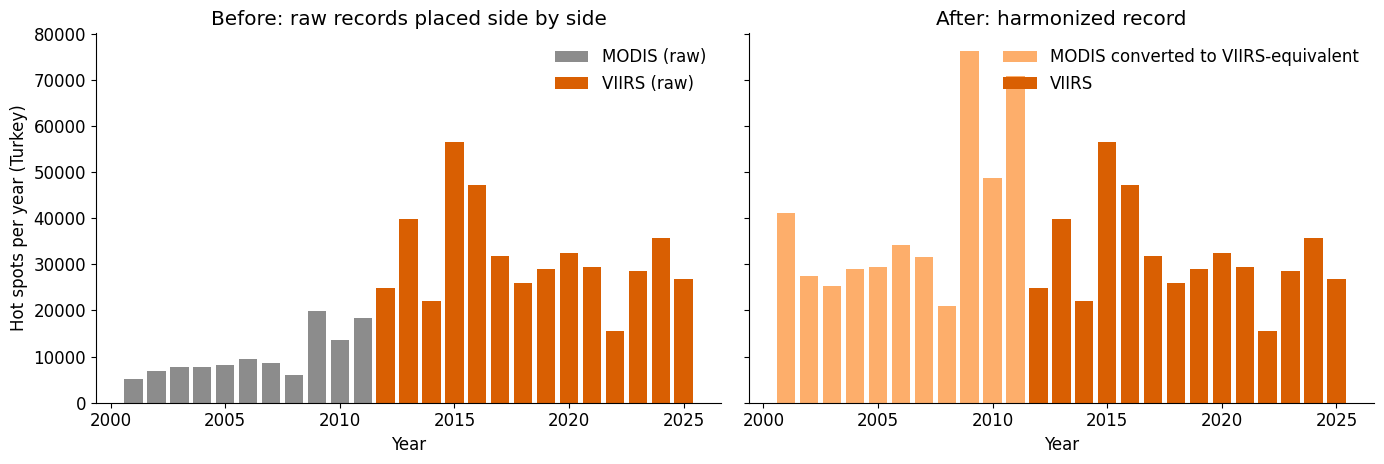

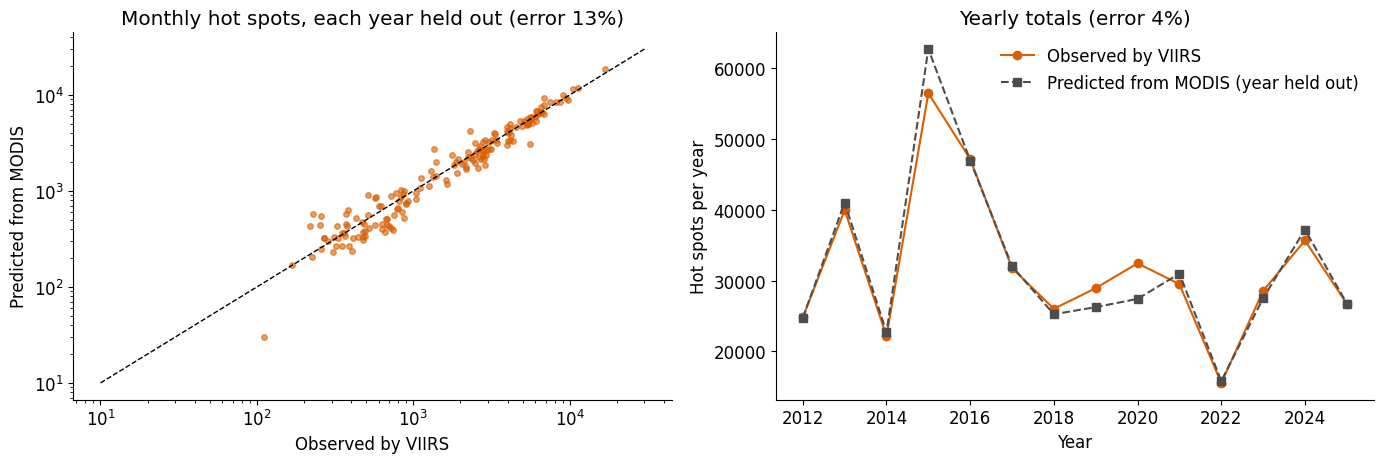

In [ ]:
import matplotlib.pyplot as plt
SUNUM = '/content/drive/MyDrive/NASA_JARVION/Sunum'
plt.rcParams.update({'font.size': 12})

ham = ay.groupby('yil').sum(min_count=1)
uyum = takvim.groupby('year')['hotspots'].sum()

# Grafik 1: uyumlaştırmadan önce ve sonra
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
ax[0].bar(ham.loc[2001:2011].index, ham.loc[2001:2011, 'MODIS'], color='#8c8c8c', label='MODIS (raw)')
ax[0].bar(ham.loc[2012:2025].index, ham.loc[2012:2025, 'SNPP'], color='#d95f02', label='VIIRS (raw)')
ax[0].set_title('Before: raw records placed side by side')
ax[1].bar(uyum.loc[2001:2011].index, uyum.loc[2001:2011], color='#fdae6b', label='MODIS converted to VIIRS-equivalent')
ax[1].bar(uyum.loc[2012:2025].index, uyum.loc[2012:2025], color='#d95f02', label='VIIRS')
ax[1].set_title('After: harmonized record')
for a in ax:
    a.set_xlabel('Year'); a.legend(frameon=False); a.spines[['top', 'right']].set_visible(False)
ax[0].set_ylabel('Hot spots per year (Turkey)')
plt.tight_layout(); plt.savefig(f'{SUNUM}/fig1_before_after.png', dpi=200); plt.show()

# Grafik 2: test - tahmin ve gerçek
s = cv['aylık katsayı']
yy = s.groupby('yil')[['SNPP', 'tahmin']].sum()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].scatter(s['SNPP'], s['tahmin'], s=16, alpha=0.6, color='#d95f02')
ax[0].plot([10, 30000], [10, 30000], 'k--', lw=1)
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('Observed by VIIRS'); ax[0].set_ylabel('Predicted from MODIS')
ax[0].set_title('Monthly hot spots, each year held out (error 13%)')
ax[1].plot(yy.index, yy['SNPP'], 'o-', color='#d95f02', label='Observed by VIIRS')
ax[1].plot(yy.index, yy['tahmin'], 's--', color='#4d4d4d', label='Predicted from MODIS (year held out)')
ax[1].set_xlabel('Year'); ax[1].set_ylabel('Hot spots per year')
ax[1].set_title('Yearly totals (error 4%)'); ax[1].legend(frameon=False)
for a in ax:
    a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(f'{SUNUM}/fig2_validation.png', dpi=200); plt.show()

In [ ]:
# İsteğiniz üzerine hata veren grafik kodu iptal edildi.
# Çalışan orijinal grafik kodunuz (fig2_validation.png) bir üst hücrede yer almaktadır.

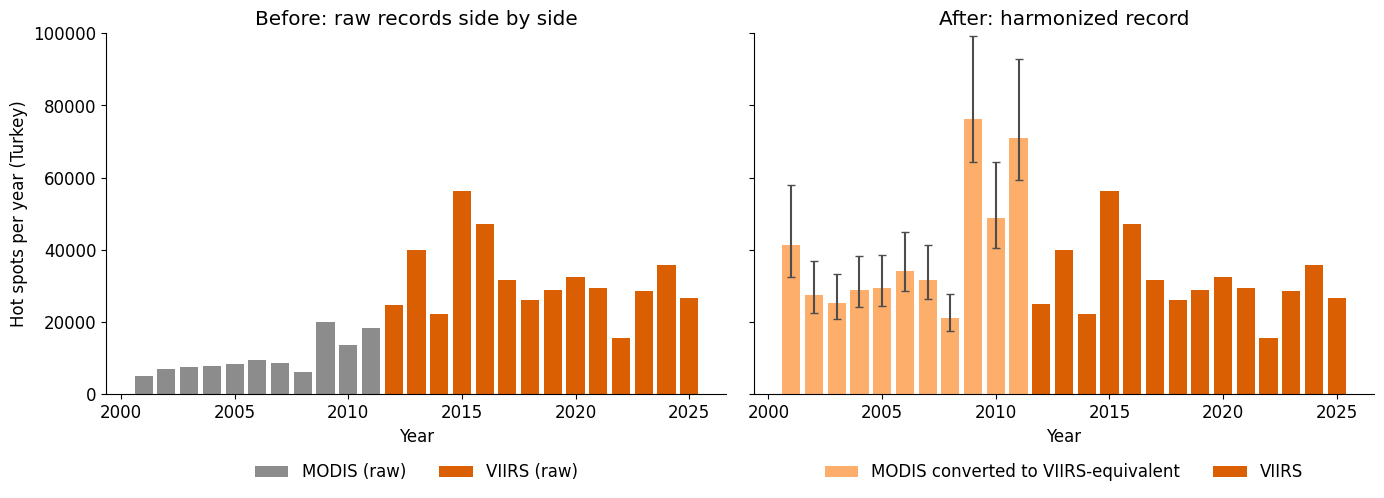

In [ ]:
lo = takvim.groupby('year')['lower'].sum()
up = takvim.groupby('year')['upper'].sum()
yr = range(2001, 2012)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
ax[0].bar(ham.loc[2001:2011].index, ham.loc[2001:2011, 'MODIS'], color='#8c8c8c', label='MODIS (raw)')
ax[0].bar(ham.loc[2012:2025].index, ham.loc[2012:2025, 'SNPP'], color='#d95f02', label='VIIRS (raw)')
ax[0].set_title('Before: raw records side by side')
ax[1].bar(uyum.loc[2001:2011].index, uyum.loc[2001:2011], color='#fdae6b',
          yerr=[uyum.loc[2001:2011] - lo.loc[2001:2011], up.loc[2001:2011] - uyum.loc[2001:2011]],
          ecolor='#4d4d4d', capsize=3, label='MODIS converted to VIIRS-equivalent')
ax[1].bar(uyum.loc[2012:2025].index, uyum.loc[2012:2025], color='#d95f02', label='VIIRS')
ax[1].set_title('After: harmonized record')
for a in ax:
    a.set_xlabel('Year')
    a.spines[['top', 'right']].set_visible(False)
    a.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
ax[0].set_ylabel('Hot spots per year (Turkey)')
ax[0].set_ylim(0, 100000)
plt.tight_layout()
plt.savefig(f'{SUNUM}/fig1_before_after.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
import plotly.express as px

d = snpp_y[(snpp_y['surum'] == 'sp') & snpp_y['yil'].between(2012, 2025)].copy()
d['period'] = np.select([d['ay'].isin([7, 8]), d['ay'].isin([9, 10])],
                        ['Jul-Aug', 'Sep-Oct'], 'other')
d = d[d['period'] != 'other']

# Bölgelere göre pay
bolgeler = {
    'Mediterranean coast': (36.0, 37.5, 27.5, 32.5),
    'Cukurova':            (36.0, 37.5, 34.5, 36.5),
    'Southeast':           (36.5, 38.5, 37.5, 42.0),
    'Aegean':              (37.5, 39.5, 26.0, 29.5),
    'Marmara and Thrace':  (40.0, 42.0, 26.0, 30.5),
}
pay = {}
for ad, (la1, la2, lo1, lo2) in bolgeler.items():
    ic = d['latitude'].between(la1, la2) & d['longitude'].between(lo1, lo2)
    pay[ad] = d[ic].groupby('period').size() / d.groupby('period').size()
print((pd.DataFrame(pay).T * 100).round(0).to_string())

# Harita
orn = d.sample(min(40000, len(d)), random_state=1)
fig = px.scatter_geo(orn, lat='latitude', lon='longitude', color='period', opacity=0.3,
                     color_discrete_map={'Jul-Aug': '#d95f02', 'Sep-Oct': '#1b9e77'},
                     title='VIIRS hot spots 2012-2025: summer vs autumn')
fig.update_traces(marker_size=3)
fig.update_geos(fitbounds='locations', showcountries=True, resolution=50)
fig.show()

period               Jul-Aug  Sep-Oct
Mediterranean coast      7.0      1.0
Cukurova                19.0     14.0
Southeast               26.0     33.0
Aegean                   5.0      4.0
Marmara and Thrace       4.0      9.0


In [ ]:
import geopandas as gpd, warnings
warnings.filterwarnings('ignore')

iller = gpd.read_file('https://raw.githubusercontent.com/alpers/Turkey-Maps-GeoJSON/master/tr-cities.json')
BOLGE = {
 'Marmara': ['Balıkesir','Bilecik','Bursa','Çanakkale','Edirne','İstanbul','Kırklareli','Kocaeli','Sakarya','Tekirdağ','Yalova'],
 'Aegean': ['Afyon','Aydın','Denizli','İzmir','Kütahya','Manisa','Muğla','Uşak'],
 'Mediterranean': ['Adana','Antalya','Burdur','Hatay','Isparta','Kahramanmaraş','Mersin','Osmaniye'],
 'Central Anatolia': ['Aksaray','Ankara','Çankırı','Eskişehir','Karaman','Kayseri','Kırıkkale','Kırşehir','Konya','Nevşehir','Niğde','Sivas','Yozgat'],
 'Black Sea': ['Amasya','Artvin','Bartın','Bayburt','Bolu','Çorum','Düzce','Giresun','Gümüşhane','Karabük','Kastamonu','Ordu','Rize','Samsun','Sinop','Tokat','Trabzon','Zonguldak'],
 'Eastern Anatolia': ['Ağrı','Ardahan','Bingöl','Bitlis','Elazığ','Erzincan','Erzurum','Hakkari','Iğdır','Kars','Malatya','Muş','Tunceli','Van'],
 'Southeastern Anatolia': ['Adıyaman','Batman','Diyarbakır','Gaziantep','Kilis','Mardin','Siirt','Şanlıurfa','Şırnak'],
}
il2b = {il: b for b, l in BOLGE.items() for il in l}
iller['region'] = iller['name'].map(il2b)
print('Bölgesi bulunamayan il:', iller.loc[iller['region'].isna(), 'name'].tolist())
iller = iller[['name', 'region', 'geometry']].rename(columns={'name': 'province'})

def il_ata(t, ad):
    t = t.reset_index(drop=True)
    g = gpd.GeoDataFrame(geometry=gpd.points_from_xy(t['longitude'], t['latitude']), crs='EPSG:4326')
    j = gpd.sjoin(g, iller, how='left', predicate='within')
    j = j[~j.index.duplicated()].sort_index()
    eksik = j['province'].isna()
    if eksik.any():
        n = gpd.sjoin_nearest(g[eksik.values].to_crs(3857), iller.to_crs(3857), how='left')
        n = n[~n.index.duplicated()]
        j.loc[n.index, ['province', 'region']] = n[['province', 'region']].values
    t['province'], t['region'] = j['province'].values, j['region'].values
    print(f'{ad}: {len(t)} nokta | %{eksik.mean()*100:.1f} sınır dışında, en yakın ile atandı')
    return t

modis_r, snpp_r, noaa20_r = il_ata(modis_y, 'MODIS'), il_ata(snpp_y, 'SNPP'), il_ata(noaa20_y, 'NOAA20')

# Kareli tabloyu bölge ve il bilgisiyle yeniden kur (katsayılar aynı)
def kareli2(t):
    t = t.assign(lat=np.floor(t['latitude'] * 2) / 2, lon=np.floor(t['longitude'] * 2) / 2)
    k = t.groupby(['yil', 'ay', 'lat', 'lon', 'region', 'province']).size().rename('n').reset_index()
    k['d'] = k['yil'] * 100 + k['ay']
    return k

gm, gs, gn = kareli2(modis_r), kareli2(snpp_r), kareli2(noaa20_r)
gm = gm[gm['d'] < 201202].copy()
gm['hotspots'] = gm['n'] * np.where(gm['d'] < 200207, gm['ay'].map(k_terra), gm['ay'].map(k_ay))
gs = gs[(gs['d'] >= 201202) & (gs['d'] < 202611)].copy(); gs['hotspots'] = gs['n']
gn = gn[gn['d'] >= 202611].copy(); gn['hotspots'] = gn['n']
grid = pd.concat([gm, gs, gn]).rename(columns={'yil': 'year', 'ay': 'month'})
grid = grid[['year', 'month', 'lat', 'lon', 'region', 'province', 'hotspots']]
grid['hotspots'] = grid['hotspots'].round(1)
grid.to_csv(f'{KOD}/grid_turkey.csv', index=False)

fark = (grid.groupby(['year', 'month'])['hotspots'].sum()
        - takvim.set_index(['year', 'month'])['hotspots']).abs().max()
print(f'\nKaydedildi: {len(grid)} satır | ülke toplamıyla en büyük fark: {fark:.1f}')

# Bölgelerin payı, yaz ve sonbahar (2012-2025, VIIRS)
d = snpp_r[snpp_r['yil'].between(2012, 2025)]
pay = pd.DataFrame({
    'Jul-Aug': d[d['ay'].isin([7, 8])]['region'].value_counts(normalize=True),
    'Sep-Oct': d[d['ay'].isin([9, 10])]['region'].value_counts(normalize=True)})
print((pay * 100).round(0).to_string())

Bölgesi bulunamayan il: []
MODIS: 251289 nokta | %0.5 sınır dışında, en yakın ile atandı
SNPP: 467321 nokta | %0.9 sınır dışında, en yakın ile atandı
NOAA20: 250339 nokta | %0.9 sınır dışında, en yakın ile atandı

Kaydedildi: 54395 satır | ülke toplamıyla en büyük fark: 5.0
                       Jul-Aug  Sep-Oct
region                                 
Aegean                    10.0      7.0
Black Sea                  3.0      5.0
Central Anatolia          15.0     18.0
Eastern Anatolia           8.0      5.0
Marmara                    5.0     10.0
Mediterranean             29.0     21.0
Southeastern Anatolia     31.0     35.0


In [ ]:
RES = 0.1   # kare boyutu (derece)

def kareli3(t):
    t = t.assign(lat=(np.floor(t['latitude'] / RES) * RES).round(2),
                 lon=(np.floor(t['longitude'] / RES) * RES).round(2))
    k = t.groupby(['yil', 'ay', 'lat', 'lon', 'region', 'province']).size().rename('n').reset_index()
    k['d'] = k['yil'] * 100 + k['ay']
    return k

gm, gs, gn = kareli3(modis_r), kareli3(snpp_r), kareli3(noaa20_r)
gm = gm[gm['d'] < 201202].copy()
gm['hotspots'] = gm['n'] * np.where(gm['d'] < 200207, gm['ay'].map(k_terra), gm['ay'].map(k_ay))
gs = gs[(gs['d'] >= 201202) & (gs['d'] < 202611)].copy(); gs['hotspots'] = gs['n']
gn = gn[gn['d'] >= 202611].copy(); gn['hotspots'] = gn['n']
grid = pd.concat([gm, gs, gn]).rename(columns={'yil': 'year', 'ay': 'month'})
grid = grid[['year', 'month', 'lat', 'lon', 'region', 'province', 'hotspots']]
grid['hotspots'] = grid['hotspots'].round(1)
grid.to_csv(f'{KOD}/grid_turkey.csv', index=False)

fark = (grid.groupby(['year', 'month'])['hotspots'].sum()
        - takvim.set_index(['year', 'month'])['hotspots']).abs().max()
mb = os.path.getsize(f'{KOD}/grid_turkey.csv') / 1e6
print(f'Kaydedildi: {len(grid)} satır | {mb:.1f} MB | ülke toplamıyla en büyük fark: {fark:.1f}')

Kaydedildi: 144794 satır | 6.6 MB | ülke toplamıyla en büyük fark: 21.1


In [ ]:
b = pd.DataFrame({'MODIS': modis_r.groupby(['region', 'yil', 'ay']).size(),
                  'SNPP': snpp_r.groupby(['region', 'yil', 'ay']).size()}).fillna(0).reset_index()
b['d'] = b['yil'] * 100 + b['ay']
b = b[(b['d'] >= 201202) & (b['d'] <= 202512)]

sonuc = []
for r, g in b.groupby('region'):
    hn = hb = 0
    for yil in sorted(g['yil'].unique()):
        t = g[g['yil'] == yil]
        en = b[b['yil'] != yil].groupby('ay')[['SNPP', 'MODIS']].sum()
        kn = en['SNPP'] / en['MODIS']
        eb = g[g['yil'] != yil].groupby('ay')[['SNPP', 'MODIS']].sum()
        kb = (eb['SNPP'] / eb['MODIS']).replace(np.inf, np.nan).fillna(kn)
        hn += (t['MODIS'] * t['ay'].map(kn) - t['SNPP']).abs().sum()
        hb += (t['MODIS'] * t['ay'].map(kb) - t['SNPP']).abs().sum()
    sonuc.append([r, round(g['SNPP'].sum() / g['MODIS'].sum(), 2),
                  round(hn / g['SNPP'].sum() * 100), round(hb / g['SNPP'].sum() * 100)])

print(pd.DataFrame(sonuc, columns=['region', 'oran (VIIRS/MODIS)',
                                   'hata %: ülke katsayısı', 'hata %: bölge katsayısı']).to_string(index=False))

               region  oran (VIIRS/MODIS)  hata %: ülke katsayısı  hata %: bölge katsayısı
               Aegean                3.47                      29                       27
            Black Sea                4.12                      31                       32
     Central Anatolia                3.36                      28                       22
     Eastern Anatolia                4.29                      23                       21
              Marmara                3.27                      27                       22
        Mediterranean                3.92                      21                       18
Southeastern Anatolia                3.05                      17                       17


In [ ]:
yb = grid.groupby(['region', 'year'])['hotspots'].sum().unstack('region')
mb = modis_r.groupby(['region', 'yil']).size().unstack('region')
yb['Türkiye'] = takvim.groupby('year')['hotspots'].sum()
mb['Türkiye'] = modis_r.groupby('yil').size()

def degisim(t):
    return ((t.loc[2017:2025].mean() / t.loc[2003:2011].mean() - 1) * 100).round(0)

tablo = pd.DataFrame({
    '2003-2011 ort.': yb.loc[2003:2011].mean().round(0),
    '2017-2025 ort.': yb.loc[2017:2025].mean().round(0),
    'değişim % (uyumlaştırılmış)': degisim(yb),
    'değişim % (sadece MODIS)': degisim(mb),
}).sort_values('değişim % (uyumlaştırılmış)')
print(tablo.to_string())

                       2003-2011 ort.  2017-2025 ort.  değişim % (uyumlaştırılmış)  değişim % (sadece MODIS)
region                                                                                                      
Central Anatolia              12871.0          3802.0                        -70.0                     -59.0
Black Sea                      2088.0          1092.0                        -48.0                     -50.0
Mediterranean                  9580.0          5307.0                        -45.0                     -53.0
Türkiye                       40712.0         28340.0                        -30.0                     -25.0
Aegean                         2892.0          2785.0                         -4.0                       0.0
Marmara                        2235.0          2241.0                          0.0                      16.0
Southeastern Anatolia         10144.0         11476.0                         13.0                      20.0
Eastern Anatolia   

In [ ]:
tablo.to_csv(f'{SUNUM}/period_change_by_region.csv')

In [ ]:
RES = 0.1   # kare boyutu (derece)

def kareli3(t):
    t = t.assign(lat=(np.floor(t['latitude'] / RES) * RES).round(2),
                 lon=(np.floor(t['longitude'] / RES) * RES).round(2))
    k = t.groupby(['yil', 'ay', 'lat', 'lon', 'region', 'province']).size().rename('n').reset_index()
    k['d'] = k['yil'] * 100 + k['ay']
    return k

gm, gs, gn = kareli3(modis_r), kareli3(snpp_r), kareli3(noaa20_r)
gm = gm[gm['d'] < 201202].copy()
gm['hotspots'] = gm['n'] * np.where(gm['d'] < 200207, gm['ay'].map(k_terra), gm['ay'].map(k_ay))
gs = gs[(gs['d'] >= 201202) & (gs['d'] < 202611)].copy(); gs['hotspots'] = gs['n']
gn = gn[gn['d'] >= 202611].copy(); gn['hotspots'] = gn['n']
grid = pd.concat([gm, gs, gn]).rename(columns={'yil': 'year', 'ay': 'month'})
grid = grid[['year', 'month', 'lat', 'lon', 'region', 'province', 'hotspots']]
grid['hotspots'] = grid['hotspots'].round(2)
grid.to_csv(f'{KOD}/grid_turkey.csv', index=False)

fark = (grid.groupby(['year', 'month'])['hotspots'].sum()
        - takvim.set_index(['year', 'month'])['hotspots']).abs().max()
mb = os.path.getsize(f'{KOD}/grid_turkey.csv') / 1e6
print(f'Kaydedildi: {len(grid)} satır | {mb:.1f} MB | ülke toplamıyla en büyük fark: {fark:.1f}')

Kaydedildi: 144794 satır | 6.6 MB | ülke toplamıyla en büyük fark: 1.9


In [ ]:
k = grid.groupby(['year', 'month'])['hotspots'].sum()
t = takvim.set_index(['year', 'month'])['hotspots']
f = pd.DataFrame({'kareler': k, 'takvim': t})
f['fark'] = f['kareler'] - f['takvim']
f['fark %'] = (f['fark'] / f['takvim'] * 100).round(2)
print(f.reindex(f['fark'].abs().sort_values(ascending=False).index).head(5).to_string())

            kareler  takvim  fark  fark %
year month                               
2011 11      3601.9    3623 -21.1   -0.58
     10     14420.8   14439 -18.2   -0.13
2001 10      9184.2    9168  16.2    0.18
2010 11      3272.8    3289 -16.2   -0.49
2009 10     16855.3   16870 -14.7   -0.09


In [ ]:
c = pd.read_csv(f'{KOD}/calendar_turkey.csv')
g = pd.read_csv(f'{KOD}/grid_turkey.csv')
sorun = []

# Takvim
if list(c.columns) != ['year','month','hotspots','lower','upper','source','confidence','note']:
    sorun.append('takvim sütunları farklı')
if len(c) != 313: sorun.append(f'takvim satır sayısı {len(c)}')
if c[['year','month']].duplicated().any(): sorun.append('takvimde tekrar eden ay')
if c[['year','month','hotspots','lower','upper','source','confidence']].isna().any().any():
    sorun.append('takvimde boş değer')
if ((c['lower'] > c['hotspots']) | (c['hotspots'] > c['upper'])).any():
    sorun.append('lower <= hotspots <= upper bozuk')
if not set(c['source']) <= {'MODIS_converted','VIIRS_SNPP','VIIRS_NOAA20'}: sorun.append('tanımsız source')
if not set(c['confidence']) <= {'high','medium','low'}: sorun.append('tanımsız confidence')
if c['note'].fillna('').str.contains(',').any(): sorun.append('note içinde virgül')
v = c[c['source'] != 'MODIS_converted']
if (v['lower'] != v['upper']).any(): sorun.append('VIIRS aylarında aralık açık')

# Kareli tablo
if list(g.columns) != ['year','month','lat','lon','region','province','hotspots']:
    sorun.append('grid sütunları farklı')
if g.isna().any().any(): sorun.append('grid içinde boş değer')
if g['region'].nunique() != 7: sorun.append(f"bölge sayısı {g['region'].nunique()}")
if not (g['lat'].between(35, 43).all() and g['lon'].between(25, 45.5).all()):
    sorun.append('Türkiye dışı koordinat')
fark = (g.groupby(['year','month'])['hotspots'].sum() - c.set_index(['year','month'])['hotspots']).abs().max()
if fark > 3: sorun.append(f'grid ve takvim toplam farkı {fark:.1f}')

print('SORUN YOK' if not sorun else '\n'.join(sorun))
print(c['source'].value_counts().to_dict(), '|', c['confidence'].value_counts().to_dict())
print(c.head(2).to_string()); print(c.tail(4).to_string())

SORUN YOK
{'VIIRS_SNPP': 177, 'MODIS_converted': 135, 'VIIRS_NOAA20': 1} | {'high': 174, 'medium': 119, 'low': 20}
   year  month  hotspots  lower  upper           source confidence                              note
0  2000     11      3175   1646   5848  MODIS_converted        low  Converted from MODIS; Terra only
1  2000     12       355    184    654  MODIS_converted        low  Converted from MODIS; Terra only
     year  month  hotspots  lower  upper        source confidence                                note
309  2026      8      2672   2672   2672    VIIRS_SNPP     medium                 Near real-time data
310  2026      9      6795   6795   6795    VIIRS_SNPP     medium                 Near real-time data
311  2026     10      4774   4774   4774    VIIRS_SNPP     medium                 Near real-time data
312  2026     11       429    429    429  VIIRS_NOAA20     medium  Partial month; near real-time data


In [ ]:
GUN = 12   # verinin son günü (12 Kasım)

def ay_basi(t):
    s = t[(t['ay'] == 11) & (t['tarih'].dt.day <= GUN)]
    return s.groupby(['yil', 'region']).size()

m, s, n = ay_basi(modis_r), ay_basi(snpp_r), ay_basi(noaa20_r)
satir = []
for (y, r), v in m.items():
    if y <= 2011:
        satir.append([y, r, v * (k_terra[11] if y < 2002 else k_ay[11]), 'MODIS_converted'])
for (y, r), v in s.items():
    if 2012 <= y <= 2025:
        satir.append([y, r, v, 'VIIRS_SNPP'])
for (y, r), v in n.items():
    if y == 2026:
        satir.append([y, r, v, 'VIIRS_NOAA20'])

mt = (pd.DataFrame(satir, columns=['year', 'region', 'hotspots', 'source'])
        .pivot_table(index='year', columns='region', values='hotspots', fill_value=0))
mt = mt.reindex(range(2000, 2027), fill_value=0).round(1)
mt.to_csv(f'{KOD}/november_1_12.csv')

tr = mt.sum(axis=1)
print(f'1-12 Kasım 2026: {tr[2026]:.0f} | 2000-2025 medyanı: {tr.loc[2000:2025].median():.0f} | '
      f'fark: %{(tr[2026] / tr.loc[2000:2025].median() - 1) * 100:.0f}')
print(mt.tail(4).to_string())

1-12 Kasım 2026: 429 | 2000-2025 medyanı: 1298 | fark: %-67
region  Aegean  Black Sea  Central Anatolia  Eastern Anatolia  Marmara  Mediterranean  Southeastern Anatolia
year                                                                                                        
2023     102.0      198.0             340.0              81.0     93.0          244.0                  704.0
2024     118.0       34.0             237.0              76.0    217.0          125.0                  795.0
2025     105.0       84.0             226.0             126.0     42.0           96.0                  668.0
2026      26.0       16.0             142.0              16.0     20.0           56.0                  153.0


In [ ]:
gun = lambda t, y: t[(t['yil'] == y) & (t['ay'] == 11) & (t['tarih'].dt.day <= 12)].groupby(t['tarih'].dt.day).size()
d = pd.DataFrame({'NOAA20 2026': gun(noaa20_r, 2026), 'SNPP 2026': gun(snpp_r, 2026),
                  'NOAA20 2025': gun(noaa20_r, 2025), 'SNPP 2025': gun(snpp_r, 2025)}).fillna(0).astype(int)
print(d.to_string())

       NOAA20 2026  SNPP 2026  NOAA20 2025  SNPP 2025
tarih                                                
1               13         11          103        114
2               12         15          141        161
3               79          0          119        102
4               20          0          182         81
5                2          0          177        117
6               11          0           75         58
7               29          0           82         83
8               51          0          173        190
9               62          0          201        227
10              12          0          153        127
11              59          0           60         85
12              79          0           98          2


In [ ]:
print(takvim[(takvim['year'] == 2011) & (takvim['month'] == 9)].to_string())
print(takvim[takvim['hotspots'] == 6207].to_string())

     year  month  hotspots  lower  upper           source confidence                  note
130  2011      9     27261  23161  35107  MODIS_converted     medium  Converted from MODIS
     year  month  hotspots  lower  upper      source confidence note
285  2024      8      6207   6207   6207  VIIRS_SNPP       high     


In [ ]:
import requests
ULKE = 'Argentina'
ARG = '/content/arg'
os.makedirs(ARG, exist_ok=True)
URL = 'https://firms.modaps.eosdis.nasa.gov/data/country/{s}/{y}/{s}_{y}_{u}.csv'

r = requests.get(URL.format(s='modis', y=2021, u=ULKE), timeout=120)
print('Durum:', r.status_code, '| Boyut:', round(len(r.content) / 1e6, 1), 'MB')
print(r.text[:300])

Durum: 200 | Boyut: 4.6 MB
latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
-32.9217,-60.2891,301.2,1.9,1.3,2021-01-01,0318,Terra,MODIS,39,6.03,285.1,16.8,N,0
-33.3875,-59.574,300.6,2,1.4,2021-01-01,0318,Terra,MODIS,31,6.03,286.4,17.7,N,0
-28.8448,


In [ ]:
def indir_oku(s, yillar):
    parcalar = []
    for y in yillar:
        yol = f'{ARG}/{s}_{y}_{ULKE}.csv'
        if not os.path.exists(yol):
            r = requests.get(URL.format(s=s, y=y, u=ULKE), timeout=300)
            if r.status_code != 200:
                print(s, y, 'İNMEDİ', r.status_code); continue
            open(yol, 'wb').write(r.content)
        parcalar.append(pd.read_csv(yol, usecols=['acq_date', 'satellite', 'type']))
    t = pd.concat(parcalar, ignore_index=True)
    t = t[t['type'] == 0].copy()
    t['tarih'] = pd.to_datetime(t['acq_date'])
    t['yil'], t['ay'] = t['tarih'].dt.year, t['tarih'].dt.month
    print(f'{s}: {len(parcalar)} dosya | {len(t)} yangın satırı')
    return t

a_modis = indir_oku('modis', range(2012, 2026))
a_snpp  = indir_oku('viirs-snpp', range(2012, 2026))

a_ay = pd.DataFrame({'MODIS': aylik(a_modis), 'SNPP': aylik(a_snpp)}).fillna(0).sort_index()
a_ortak = a_ay.loc[(2012, 2):(2025, 12)]
a_o = a_ortak.reset_index()

print('\nArjantin genel katsayı:', round(a_ortak['SNPP'].sum() / a_ortak['MODIS'].sum(), 2),
      '| Türkiye:', round(k_genel, 2))
for model in ['tek katsayı', 'aylık katsayı', 'eğri']:
    p = []
    for yil in sorted(a_o['yil'].unique()):
        e, t = a_o[a_o['yil'] != yil], a_o[a_o['yil'] == yil].copy()
        t['tahmin'] = tahmin_et(e, t, model)
        p.append(t)
    s = pd.concat(p)
    y = s.groupby('yil')[['tahmin', 'SNPP']].sum()
    print(f"{model:14s} | aylık hata: %{(s['tahmin'] - s['SNPP']).abs().sum() / s['SNPP'].sum() * 100:.0f}"
          f" | yıllık toplam hatası: %{((y['tahmin'] - y['SNPP']).abs() / y['SNPP']).mean() * 100:.0f}")

ga = a_ortak.groupby('ay')[['SNPP', 'MODIS']].sum()
karsilastirma = pd.DataFrame({'Türkiye': k_ay.round(2), 'Arjantin': (ga['SNPP'] / ga['MODIS']).round(2)})
karsilastirma.to_csv(f'{SUNUM}/factors_turkey_vs_argentina.csv')
print('\nAylık katsayılar:'); print(karsilastirma.to_string())

modis: 14 dosya | 812102 yangın satırı
viirs-snpp: 14 dosya | 2800306 yangın satırı

Arjantin genel katsayı: 3.47 | Türkiye: 3.38
tek katsayı    | aylık hata: %12 | yıllık toplam hatası: %6
aylık katsayı  | aylık hata: %9 | yıllık toplam hatası: %5
eğri           | aylık hata: %12 | yıllık toplam hatası: %6

Aylık katsayılar:
    Türkiye  Arjantin
ay                   
1      3.10      4.02
2      3.02      4.09
3      3.58      3.96
4      3.71      3.62
5      1.82      3.48
6      2.13      3.29
7      3.16      3.08
8      4.39      3.07
9      4.77      3.30
10     3.91      3.66
11     2.55      3.94
12     3.01      3.88


In [ ]:
import pandas as pd
from calendar import monthrange

KOD = '/content/drive/MyDrive/NASA_JARVION/Kod'

# 1) Her sensörün verisi hangi güne kadar uzanıyor (ham tablolardan)
son = {'MODIS':  modis.tarih.max().date(),
       'SNPP':   snpp.tarih.max().date(),
       'NOAA20': noaa20.tarih.max().date()}
print('Veri bitiş tarihleri:', son)

# 2) Takvimi oku
tk = pd.read_csv(f'{KOD}/calendar_turkey.csv')

# 3) Her satır: ay kaç gün, ve o ayın kaç günü veriyle kaplı
SENSOR = {'MODIS_converted': 'MODIS',
          'VIIRS_SNPP':      'SNPP',
          'VIIRS_NOAA20':    'NOAA20'}

def kapsama(r):
    y, m = int(r.year), int(r.month)
    ayin_gunu = monthrange(y, m)[1]
    bitis = son[SENSOR[r.source]]
    if (bitis.year, bitis.month) == (y, m):      # verinin bittiği ay
        return min(bitis.day, ayin_gunu), ayin_gunu
    return ayin_gunu, ayin_gunu                   # tam ay

tk[['days_with_data','days_in_month']] = tk.apply(
    lambda r: pd.Series(kapsama(r)), axis=1)

# 4) Kontrol: SADECE Kasım 2026 eksik çıkmalı
eksik = tk[tk.days_with_data < tk.days_in_month]
print('\nEksik ay sayisi:', len(eksik))
print(eksik[['year','month','hotspots','source','days_with_data','days_in_month','note']])

tk.to_csv(f'{KOD}/calendar_turkey.csv', index=False)
print('\nYazildi. Satir:', len(tk), '| Sutunlar:', list(tk.columns))

Veri bitiş tarihleri: {'MODIS': datetime.date(2026, 11, 13), 'SNPP': datetime.date(2026, 11, 2), 'NOAA20': datetime.date(2026, 11, 12)}

Eksik ay sayisi: 1
     year  month  hotspots        source  days_with_data  days_in_month  \
312  2026     11       429  VIIRS_NOAA20              12             30   

                                   note  
312  Partial month; near real-time data  

Yazildi. Satir: 313 | Sutunlar: ['year', 'month', 'hotspots', 'lower', 'upper', 'source', 'confidence', 'note', 'days_with_data', 'days_in_month']


In [ ]:
n12 = pd.read_csv(f'{KOD}/november_1_12.csv')
print('Sutunlar:', n12.columns.tolist())
print('\n2026:')
print(n12[n12.year == 2026])
print('\n2000-2025 medyani (her sutun):')
print(n12[n12.year <= 2025].drop(columns='year').median().round(0))

Sutunlar: ['year', 'Aegean', 'Black Sea', 'Central Anatolia', 'Eastern Anatolia', 'Marmara', 'Mediterranean', 'Southeastern Anatolia']

2026:
    year  Aegean  Black Sea  Central Anatolia  Eastern Anatolia  Marmara  \
26  2026    26.0       16.0             142.0              16.0     20.0   

    Mediterranean  Southeastern Anatolia  
26           56.0                  153.0  

2000-2025 medyani (her sutun):
Aegean                   104.0
Black Sea                 39.0
Central Anatolia         234.0
Eastern Anatolia          29.0
Marmara                   64.0
Mediterranean            194.0
Southeastern Anatolia    346.0
dtype: float64


In [ ]:
BOLGELER = ['Aegean','Black Sea','Central Anatolia','Eastern Anatolia',
            'Marmara','Mediterranean','Southeastern Anatolia']

n12['Turkey'] = n12[BOLGELER].sum(axis=1)
n12.to_csv(f'{KOD}/november_1_12.csv', index=False)

print('Sutunlar:', n12.columns.tolist())
print('2026 Turkiye      :', int(n12.loc[n12.year==2026,'Turkey'].iloc[0]))
print('2000-2025 medyani :', int(n12.loc[n12.year<=2025,'Turkey'].median()))

t = pd.DataFrame({
    'y2026':  n12.loc[n12.year==2026, BOLGELER+['Turkey']].iloc[0],
    'medyan': n12.loc[n12.year<=2025, BOLGELER+['Turkey']].median().round(0)})
t['degisim_%'] = ((t.y2026/t.medyan - 1)*100).round(0)
print('\n', t)

Sutunlar: ['year', 'Aegean', 'Black Sea', 'Central Anatolia', 'Eastern Anatolia', 'Marmara', 'Mediterranean', 'Southeastern Anatolia', 'Turkey']
2026 Turkiye      : 429
2000-2025 medyani : 1297

                        y2026  medyan  degisim_%
Aegean                  26.0   104.0      -75.0
Black Sea               16.0    39.0      -59.0
Central Anatolia       142.0   234.0      -39.0
Eastern Anatolia        16.0    29.0      -45.0
Marmara                 20.0    64.0      -69.0
Mediterranean           56.0   194.0      -71.0
Southeastern Anatolia  153.0   346.0      -56.0
Turkey                 429.0  1298.0      -67.0
